# ZeRO on 32 Virtual GPUs

**ERA V5 · Session 12 — Distributed Training I: Data Parallel and ZeRO.**

The assignment: build 32 virtual GPUs, run a demo model on them, simulate plain data parallelism, ZeRO-1, ZeRO-2 and ZeRO-3, and show how memory and computation change. The instructor's extra line in class was the one I took most seriously: *"make sure that it matches what ZeRO does."* So every number in this notebook is checked twice, against the lesson's formulas and against PyTorch's own implementations running on 32 real processes.

| § | What | The one-line answer |
|---|---|---|
| [1](#1) | The 32 virtual GPUs | 32 threads, 4 "nodes" of 8, ring collectives that pass real messages and count every byte |
| [2](#2) | The demo model | the Session 10/11 character GPT, shrunk to 818K parameters and cut into 6 shardable units |
| [3](#3) | Same model, four ways | all four arrangements produce **bit-identical** weights; ZeRO changes where things live, not the maths |
| [4](#4) | Memory | 16 → 4 + 12/N → 2 + 14/N → 16/N, measured per category, plus what the formulas leave out: the peaks |
| [5](#5) | Communication | 2P, 2P, 2P, 3P, measured as 2(N−1)/N and 3(N−1)/N |
| [6](#6) | Computation and time | the FLOPs never change; the optimizer shrinks N×; the network share reproduces the lesson's 34% / 77% |
| [7](#7) | Offload | GPU memory for PCIe bandwidth |
| [8](#8) | Scaling to V5 | my measured bytes/param times 30B = the lesson's memory ladder |
| [9](#9) | Reality check | DDP, ZeroRedundancyOptimizer and FSDP2 on 32 real processes |
| [10](#10) | What I would pick | pros and cons of each stage |

## 0 · Setup

`S12_PROFILE=full` (default) is the reported run: 32 virtual GPUs. `S12_PROFILE=quick` uses 8 and a few steps, just to check every cell runs.

In [1]:
import os, json, time, math
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from s12 import theory as T, plots as PL
from s12.zero import RunCfg, run, NAMES, unit_flops, Layout, ADAM_BYTES
from s12.model import CharData, build, unit_names
from s12.vgpu import Cluster, CATS, STATE, LABEL
from s12.hw import calibrated, CARD_GIB, GIB, lesson_step_seconds
from s12.style import fmt_bytes

PROFILE = os.environ.get('S12_PROFILE', 'full')
QUICK = PROFILE == 'quick'
WORLD, STEPS = (8, 8) if QUICK else (32, 100)
data = CharData()
SUMMARY = {'profile': PROFILE, 'world': WORLD, 'steps': STEPS, 'torch': torch.__version__}
SITE = {'world': WORLD, 'gpus_per_node': 8}
md = lambda s: display(Markdown(s))
pd.set_option('display.precision', 4)
pd.set_option('display.width', 160)
print(f'profile={PROFILE} · {WORLD} virtual GPUs · {STEPS} steps · torch {torch.__version__} · {os.cpu_count()} CPU threads')

profile=full · 32 virtual GPUs · 100 steps · torch 2.15.0+cpu · 32 CPU threads


<a id="1"></a>
## 1 · The 32 virtual GPUs

Each virtual GPU is a Python thread with three things:

* **A memory ledger.** Every tensor the GPU keeps (weights, gradients, master copy, Adam's m and v, a gathered layer, a gradient bucket, activations) is registered with its *real* byte size and freed explicitly. "How much does GPU 7 hold right now" is a sum over live tensors, not a formula. The ledger asserts on every double-allocation, so a leak shows up as a crash, not a slow drift.
* **A mailbox.** The only way data reaches a GPU is a message from another GPU. The collectives are the **ring** algorithms NCCL uses: every GPU sends only to its right-hand neighbour, `N−1` times per phase.
* **Clocks**, one per stream (compute, all-gather, reduce-scatter, PCIe), like CUDA streams. A message takes `bytes / bandwidth` of the link it crosses: 450 GB/s NVLink inside a node, 50 GB/s InfiniBand between nodes. A send cannot start before the receiver has entered the collective. That gives every step a simulated duration, with real overlap and real waiting.

The 32 are laid out like the lesson's world size of 32: 4 nodes × 8 GPUs.

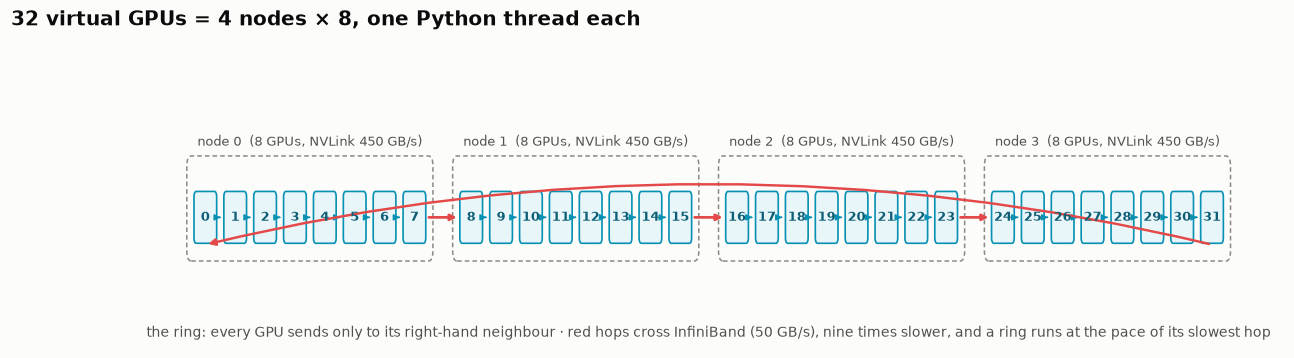

In [2]:
PL.cluster(WORLD, 8)

### The collectives, checked before anything is built on them

Section 4 of the lesson: *a reduce-scatter followed by an all-gather is an all-reduce, and the pair costs the same as the whole.* I check that on the 32 GPUs with random fp64 data, in both modes of my cluster. `mailbox` sends every ring hop as a real message between threads. `rendezvous` lets all ranks meet at a barrier and has one thread play the identical ring hop by hop, which is much faster in Python (timed below). `tests/test_core.py` checks the two give bit-identical training runs.

In [3]:
torch.manual_seed(0)
xs = [torch.randn(WORLD * 1024, dtype=torch.float64) for _ in range(WORLD)]
exact = torch.stack(xs).sum(0)

def collectives(g):
    shard, _ = g.reduce_scatter(xs[g.rank], 'reduce-scatter')
    full, _ = g.all_gather(shard, 'all-gather')
    ar, _ = g.all_reduce(xs[g.rank], 'all-reduce')
    return shard, full, ar, {k[0]: v for k, v in g.sent.items()}

rows = []
for mode in ('mailbox', 'rendezvous'):
    t0 = time.perf_counter()
    out = Cluster(WORLD, calibrated(), mode=mode).run(collectives)
    dt = time.perf_counter() - t0
    tensor_bytes = xs[0].numel() * 8
    rows.append({
        'mode': mode,
        'max |RS slice − exact sum|': max((o[0] - exact.view(WORLD, -1)[r]).abs().max().item() for r, o in enumerate(out)),
        'RS→AG == all-reduce (bits)': all(torch.equal(o[1], o[2]) for o in out),
        'all ranks identical (bits)': all(torch.equal(o[1], out[0][1]) for o in out),
        'RS bytes sent / tensor': out[0][3]['reduce-scatter'] / tensor_bytes,
        'AG bytes sent / tensor': out[0][3]['all-gather'] / tensor_bytes,
        'all-reduce bytes / tensor': out[0][3]['all-reduce'] / tensor_bytes,
        'wall (s)': round(dt, 2)})
display(pd.DataFrame(rows).set_index('mode'))
print(f'(N−1)/N = {(WORLD - 1) / WORLD:.5f}   2(N−1)/N = {2 * (WORLD - 1) / WORLD:.5f}')
SUMMARY['collectives'] = rows

,max |RS slice − exact sum|,RS→AG == all-reduce (bits),all ranks identical (bits),RS bytes sent / tensor,AG bytes sent / tensor,all-reduce bytes / tensor,wall (s)
mode,,,,,,,
mailbox,1.0658e-14,True,True,0.9688,0.9688,1.9375,0.59
rendezvous,1.0658e-14,True,True,0.9688,0.9688,1.9375,0.12


(N−1)/N = 0.96875   2(N−1)/N = 1.93750


<a id="2"></a>
## 2 · The demo model

The Session 10/11 character-level GPT on TinyShakespeare, shrunk so 32 copies fit on a laptop: 4 layers, width 128, 4 heads, context 64. It is cut into **units**: the embeddings, each block, and the head. A unit is what ZeRO-3 gathers and frees as one piece (FSDP's FlatParameter; in FSDP2, whatever `fully_shard()` was called on). Each unit is flattened, padded so it splits into `N` equal contiguous slices, and each GPU *owns* one slice.

Precision follows the lesson: **bf16 weights and gradients (2 + 2 B), fp32 master copy (4 B), fp32 Adam m and v (4 + 4 B)** = 16 B per parameter. My CPU has no bf16 matmul units (I measured bf16 at 8× slower than fp32), so the matmuls run on fp32 copies of the bf16 weights: bf16 in, fp32 accumulate, which is also what a tensor core does. The ledger counts what a GPU would store: the bf16 tensors.

Every GPU sees 4 sequences of 64 characters per step (256 tokens), so the global batch is 4 × 32 = 128 sequences.

In [4]:
cfg0 = RunCfg(world=WORLD)
model = build(cfg0.model)
fl = unit_flops(cfg0)
rows = []
for nm, u, f in zip(unit_names(cfg0.model), model.units, fl):
    L = Layout(u, WORLD)
    rows.append({'unit': nm, 'parameters': L.numel, 'padded to': L.padded, 'slice per GPU': L.chunk,
                 'fwd MFLOP / GPU': f['fwd'] / 1e6, 'bwd MFLOP / GPU': f['bwd'] / 1e6})
units = pd.DataFrame(rows)
units.loc['total'] = units.sum(numeric_only=True)
units.loc['total', 'unit'] = 'total'
display(units)
PSI = int(units.loc['total', 'parameters'])
PSI_PAD = int(units.loc['total', 'padded to'])
print(f'Ψ = {PSI:,} parameters · padded {PSI_PAD:,} (+{PSI_PAD / PSI - 1:.2%}) · P = {2 * PSI / 2**20:.3f} MiB in bf16')
print(f'forward+backward = {(units.loc["total", "fwd MFLOP / GPU"] + units.loc["total", "bwd MFLOP / GPU"]) / (6 * PSI * 256 / 1e6):.3f} × the 6·Ψ·tokens rule')
SUMMARY.update(psi=PSI, psi_padded=PSI_PAD)

,unit,parameters,padded to,slice per GPU,fwd MFLOP / GPU,bwd MFLOP / GPU
0,embed,16512,16896,528,0.0000,0.0000
1,block0,198272,198656,6208,109.0519,222.2981
2,block1,198272,198656,6208,109.0519,222.2981
3,block2,198272,198656,6208,109.0519,222.2981
4,block3,198272,198656,6208,109.0519,222.2981
5,head,8641,8704,272,4.2598,8.5197
total,total,818241,820224,25632,440.4675,897.7121


Ψ = 818,241 parameters · padded 820,224 (+0.24%) · P = 1.561 MiB in bf16
forward+backward = 1.065 × the 6·Ψ·tokens rule


<a id="3"></a>
## 3 · The same model, four ways

One training loop, four arrangements. Each GPU runs the same SPMD function; the arrangements differ only in what each GPU keeps and which collective it calls:

| | keeps in full | keeps 1/N of | gradients leave by | new weights arrive by |
|---|---|---|---|---|
| **DDP** | W, G, master, m, v | — | all-reduce (= reduce-scatter + all-gather) | each GPU casts its own |
| **ZeRO-1** | W, G | master, m, v | reduce-scatter | all-gather of bf16 slices |
| **ZeRO-2** | W | G, master, m, v | reduce-scatter, one bucket at a time | all-gather of bf16 slices |
| **ZeRO-3** | — | W, G, master, m, v | reduce-scatter, one bucket at a time | nothing: each layer is all-gathered when the forward or backward pass reaches it, then freed |

Gradient clipping needs the global norm, which needs every slice. Each GPU sums the squares of its own slice and the 32 partial sums are all-gathered (32 floats) and added in rank order. DDP has every slice locally and does the same sum. That is what keeps the arrangements bit-identical.

In [5]:
R = {st: run(RunCfg(stage=st, world=WORLD, steps=STEPS), data) for st in range(4)}

rows = []
for st, r in R.items():
    rows.append({'arrangement': NAMES[st], 'final loss': r.losses[-1],
                 'loss == DDP at every step': r.losses == R[0].losses,
                 'fp32 master == DDP (all bits)': torch.equal(r.full('_master'), R[0].full('_master')),
                 'bf16 weights == DDP (all bits)': torch.equal(r.full('_W'), R[0].full('_W')),
                 'wall (s)': round(r.wall_s)})
display(pd.DataFrame(rows).set_index('arrangement'))
SUMMARY['same_model'] = rows
SUMMARY['final_loss'] = R[0].losses[-1]
for r in R.values():
    r.drop_weights()          # checked; free the per-GPU weight copies (this laptop has 8 GB for 32 GPUs)
SITE['losses'] = R[0].losses
SITE['gnorms'] = [sum(x['gnorms'][k] for x in R[0].ranks) / WORLD for k in range(STEPS)]

DDP                    N=32  16.039 B/param  sent 1.942 P  loss 2.3403  (401s)


ZeRO-1                 N=32   4.386 B/param  sent 1.942 P  loss 2.3403  (269s)


ZeRO-2                 N=32   2.443 B/param  sent 1.942 P  loss 2.3403  (262s)


ZeRO-3                 N=32   0.501 B/param  sent 2.913 P  loss 2.3403  (287s)


,final loss,loss == DDP at every step,fp32 master == DDP (all bits),bf16 weights == DDP (all bits),wall (s)
arrangement,,,,,
DDP,2.3403,True,True,True,401
ZeRO-1,2.3403,True,True,True,269
ZeRO-2,2.3403,True,True,True,262
ZeRO-3,2.3403,True,True,True,287


**Is data parallelism really "one GPU with a 32× bigger batch"?** Section 3 of the lesson says the averaged gradient is exactly the big-batch gradient. Two checks: one GPU fed the whole 128-sequence batch in fp64, against ZeRO-3 on 32 GPUs in fp64; and the same pair in the real bf16 setup.

In [6]:
F1 = run(RunCfg(stage=0, world=1, micro_bs=4 * WORLD, steps=10, dtype='fp64'), data)
FN = run(RunCfg(stage=3, world=WORLD, steps=10, dtype='fp64'), data)
ONE = run(RunCfg(stage=0, world=1, micro_bs=4 * WORLD, steps=STEPS), data)
d64 = (F1.full() - FN.full()).abs().max().item()
F1.drop_weights(), FN.drop_weights(), ONE.drop_weights()
dl = np.abs(np.array(ONE.losses) - np.array(R[0].losses))
md(f'* **fp64:** after 10 steps the largest difference in any of the {PSI:,} weights between 1 GPU and ZeRO-3 on {WORLD} '
   f'is **{d64:.1e}**: summation-order rounding, nothing more.\n'
   f'* **bf16:** the loss curves differ by up to **{dl.max():.4f}** (mean {dl.mean():.4f}). The 32 gradients are summed hop by '
   f'hop around the ring *in bf16*, which rounds 31 times; one GPU accumulates in fp32 and rounds once. Same maths, '
   f'different rounding: this is why some frameworks reduce gradients in fp32.')
SUMMARY.update(fp64_max_weight_diff=d64, bf16_one_gpu_loss_diff_max=float(dl.max()))
SITE['one_gpu_losses'] = ONE.losses

DDP [fp64]             N=1   40.001 B/param  sent 0.000 P  loss 3.0386  (20s)


ZeRO-3 [fp64]          N=32   1.253 B/param  sent 2.913 P  loss 3.0386  (27s)


DDP                    N=1   16.000 B/param  sent 0.000 P  loss 2.3404  (69s)


* **fp64:** after 10 steps the largest difference in any of the 818,241 weights between 1 GPU and ZeRO-3 on 32 is **2.4e-15**: summation-order rounding, nothing more.
* **bf16:** the loss curves differ by up to **0.0057** (mean 0.0012). The 32 gradients are summed hop by hop around the ring *in bf16*, which rounds 31 times; one GPU accumulates in fp32 and rounds once. Same maths, different rounding: this is why some frameworks reduce gradients in fp32.

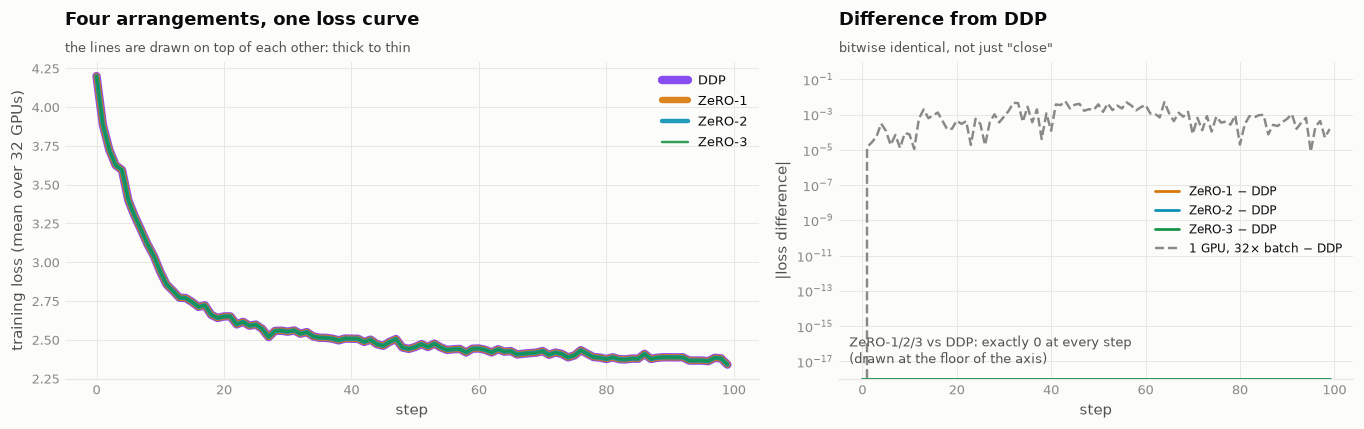

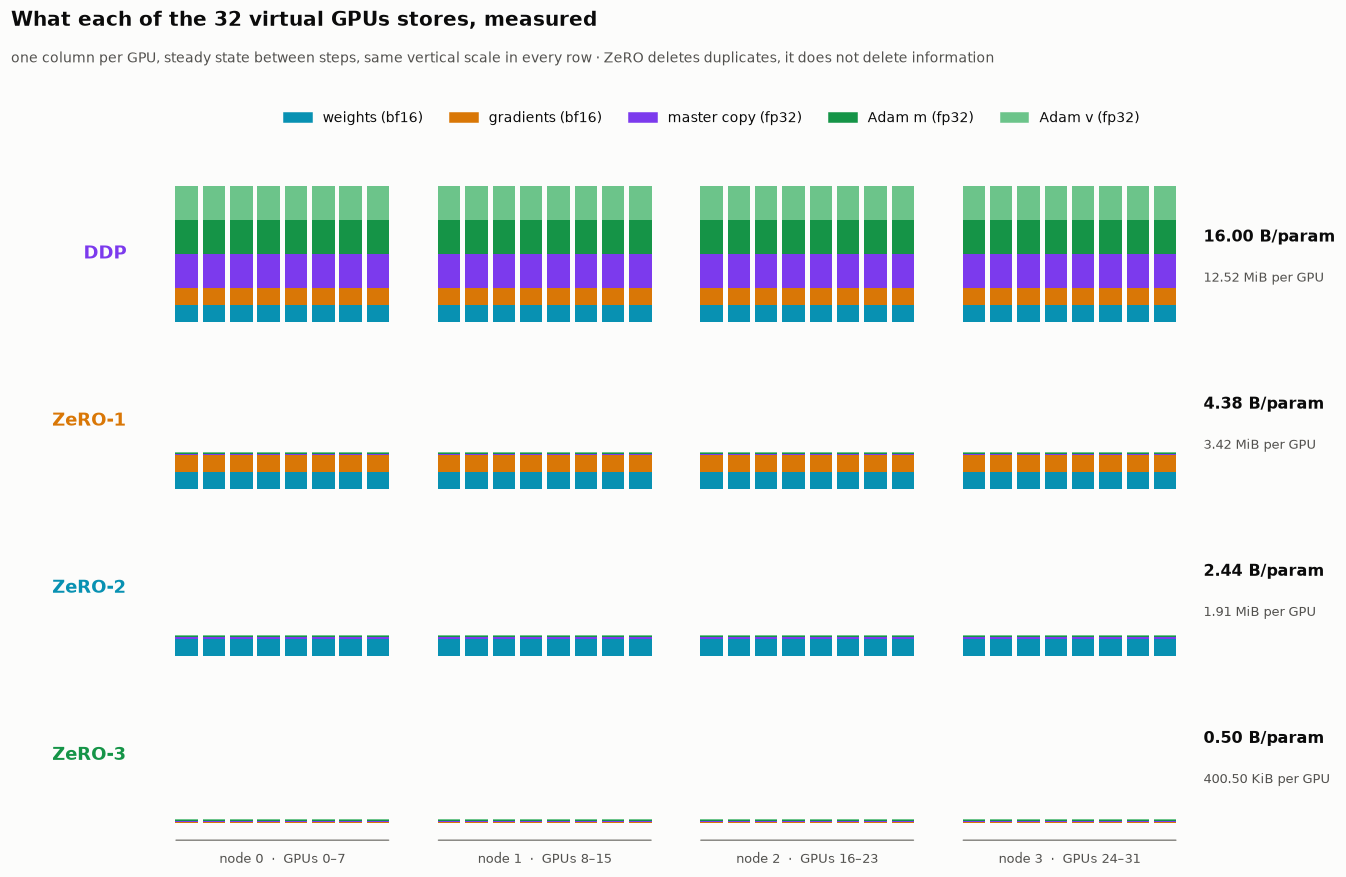

In [7]:
PL.losses(R, ONE)
PL.hero(R)

<a id="4"></a>
## 4 · Memory

### What each GPU holds, against the lesson's formula

The ledger of GPU 0 between steps, per category, divided by the parameter count. The lesson's numbers are per *stored* element, so I divide by the padded count for the comparison and also show the true-count figure.

In [8]:
OFF = {st: run(RunCfg(stage=st, world=WORLD, steps=3, offload=True), data, keep_weights=False) for st in (1, 2, 3)}
for st, r in OFF.items():
    assert r.losses == R[st].losses[:3], 'offload changed the maths'

rows = []
for r in [R[0], R[1], R[2], R[3], OFF[1], OFF[2], OFF[3]]:
    st, off = r.cfg.stage, r.cfg.offload
    m = r.ranks[0]['steady']
    row = {'arrangement': r.cfg.name}
    for c in STATE:
        row[c] = m[c] / r.psi_padded
    row['measured B/param'] = r.bytes_per_param(padded=True)
    row['lesson formula'] = T.bytes_per_param(st, WORLD, offload=off)
    row['B/param (true Ψ)'] = r.bytes_per_param()
    row['GPU MiB'] = r.gpu_bytes() / 2**20
    row['peak MiB'] = r.ranks[0]['peak'] / 2**20
    row['peak during'] = r.ranks[0]['peak_phase']
    row['CPU MiB'] = sum(r.ranks[0]['host_steady'].values()) / 2**20
    rows.append(row)
mem = pd.DataFrame(rows).set_index('arrangement')
display(mem.style.format(precision=4))
assert np.allclose(mem['measured B/param'], mem['lesson formula'], atol=1e-12)
SUMMARY['memory'] = mem.reset_index().to_dict('records')

ZeRO-1 + offload       N=32   4.010 B/param  sent 1.942 P  loss 3.7258  (8s)


ZeRO-2 + offload       N=32   2.067 B/param  sent 1.942 P  loss 3.7258  (9s)


ZeRO-3 + offload       N=32   0.125 B/param  sent 2.913 P  loss 3.7258  (8s)


,weights,grads,master,adam_m,adam_v,measured B/param,lesson formula,B/param (true Ψ),GPU MiB,peak MiB,peak during,CPU MiB
arrangement,,,,,,,,,,,,
DDP,2.0000,2.0000,4.0000,4.0000,4.0000,16.0000,16.0000,16.0388,12.5156,20.9878,fwd head,0.0000
ZeRO-1,2.0000,2.0000,0.1250,0.1250,0.1250,4.3750,4.3750,4.3856,3.4222,11.8944,fwd head,0.0000
ZeRO-2,2.0000,0.0625,0.1250,0.1250,0.1250,2.4375,2.4375,2.4434,1.9067,10.3788,fwd head,0.0000
ZeRO-3,0.0625,0.0625,0.1250,0.1250,0.1250,0.5000,0.5000,0.5012,0.3911,8.8799,fwd head,0.0000
ZeRO-1 + offload,2.0000,2.0000,0.0000,0.0000,0.0000,4.0000,4.0000,4.0097,3.1289,11.6011,fwd head,0.2933
ZeRO-2 + offload,2.0000,0.0625,0.0000,0.0000,0.0000,2.0625,2.0625,2.0675,1.6133,10.0855,fwd head,0.2933
ZeRO-3 + offload,0.0625,0.0625,0.0000,0.0000,0.0000,0.1250,0.1250,0.1253,0.0978,8.5866,fwd head,0.2933


The steady-state numbers match the formula to the last digit. The **peak** column is what the formula does not tell you. Inside a step a GPU also holds activations, and (ZeRO-2/3) a gradient bucket or a gathered layer that exists for a few microseconds. On a real card the peak, not the steady state, decides whether you crash.

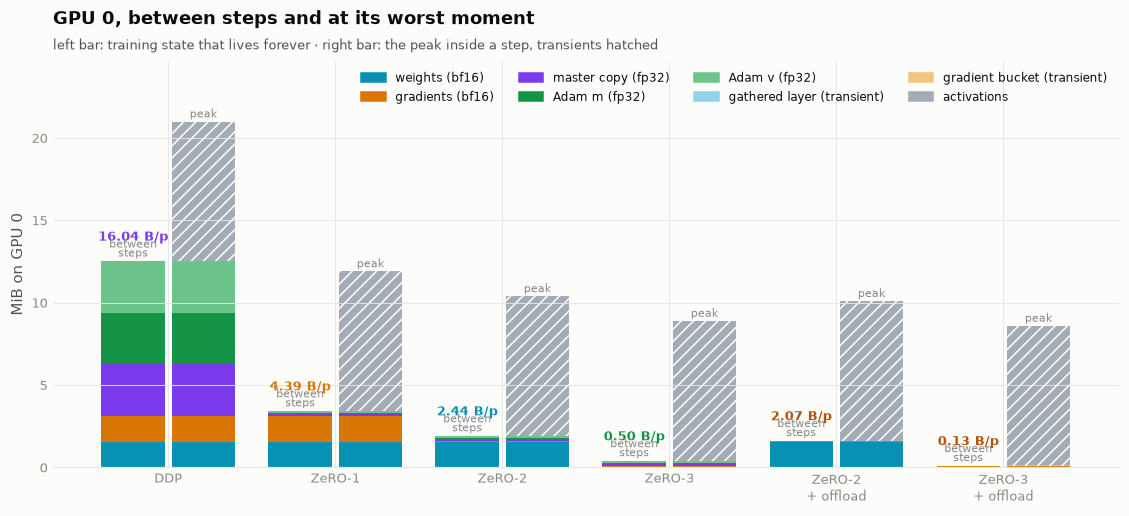

In [9]:
PL.memory_bars([R[0], R[1], R[2], R[3], OFF[2], OFF[3]])

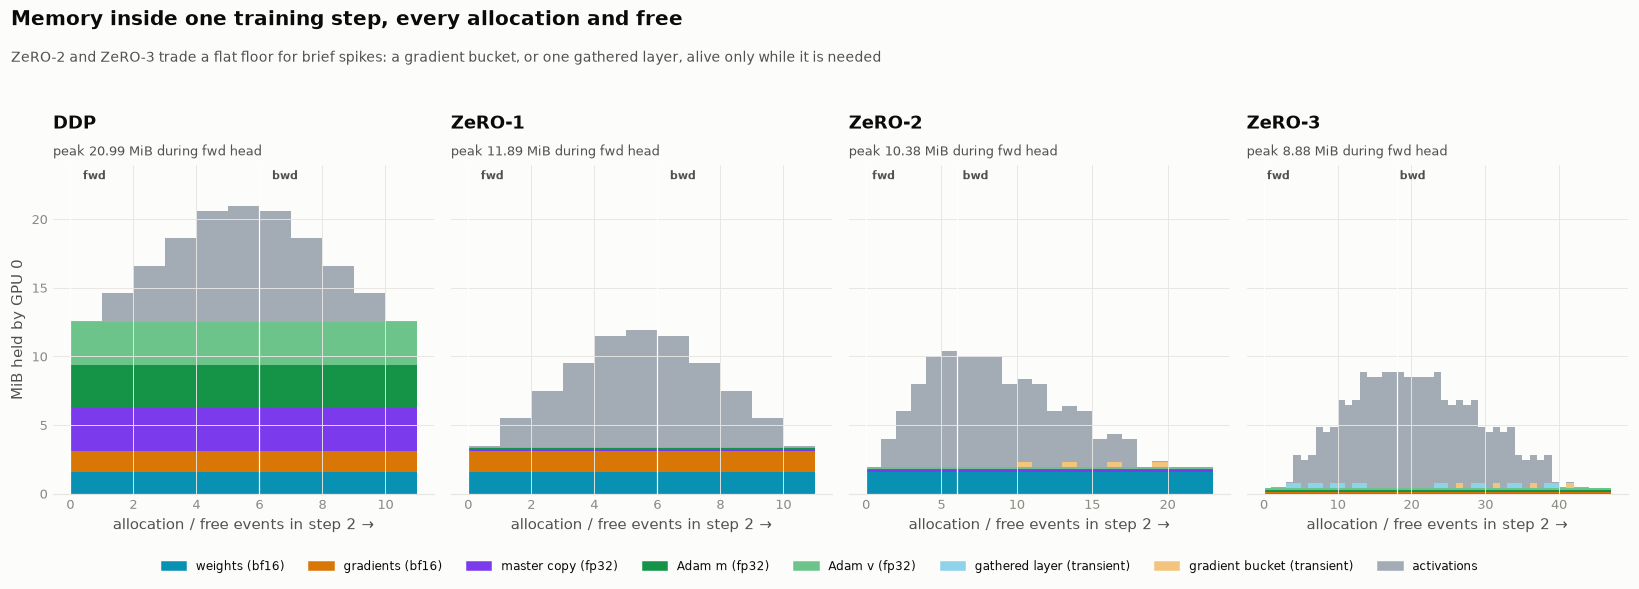

DDP     steady  12.52 MiB   peak  20.99 MiB during fwd head     activations 8.47 MiB
ZeRO-1  steady   3.42 MiB   peak  11.89 MiB during fwd head     activations 8.47 MiB
ZeRO-2  steady   1.91 MiB   peak  10.38 MiB during fwd head     activations 8.47 MiB
ZeRO-3  steady 400.50 KiB   peak   8.88 MiB during fwd head     gathered layer 17.00 KiB  activations 8.47 MiB


In [10]:
PL.memory_timeline(R)
for st in range(4):
    p = R[st].ranks[0]
    trans = {c: p['peak_cat'][c] for c in ('gathered', 'grad_bucket', 'activations')}
    print(f"{NAMES[st]:<7} steady {fmt_bytes(R[st].gpu_bytes()):>10}   peak {fmt_bytes(p['peak']):>10} during {p['peak_phase']:<12} "
          + '  '.join(f'{LABEL[c].split(" (")[0]} {fmt_bytes(v)}' for c, v in trans.items() if v))

### Does it hold for every N?

Each arrangement at N = 1, 2, 4, 8, 16, 32 (one node up to 8 GPUs, then 8 per node).

,DDP measured,DDP formula,ZeRO-1 measured,ZeRO-1 formula,ZeRO-2 measured,ZeRO-2 formula,ZeRO-3 measured,ZeRO-3 formula
N,,,,,,,,
1,16.0000,16,16.0000,16.0000,16.0000,16.0000,16.0000,16.0000
2,16.0000,16,10.0000,10.0000,9.0000,9.0000,8.0000,8.0000
4,16.0000,16,7.0000,7.0000,5.5000,5.5000,4.0000,4.0000
8,16.0000,16,5.5000,5.5000,3.7500,3.7500,2.0000,2.0000
16,16.0000,16,4.7500,4.7500,2.8750,2.8750,1.0000,1.0000
32,16.0000,16,4.3750,4.3750,2.4375,2.4375,0.5000,0.5000


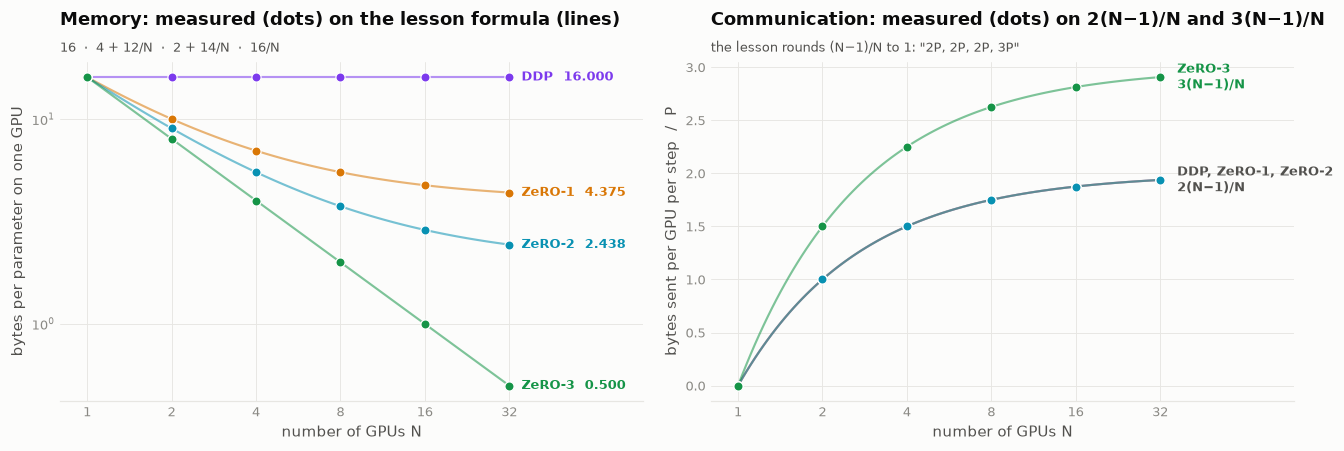

In [11]:
NS = [1, 2, 4, 8] if QUICK else [1, 2, 4, 8, 16, 32]
SW = {(st, n): run(RunCfg(stage=st, world=n, gpus_per_node=min(8, n), steps=3), data, quiet=True, keep_weights=False)
      for st in range(4) for n in NS}
tab = pd.DataFrame({f'{NAMES[st]} measured': [SW[(st, n)].bytes_per_param(padded=True) for n in NS] for st in range(4)}, index=NS)
for st in range(4):
    tab[f'{NAMES[st]} formula'] = [T.bytes_per_param(st, n) for n in NS]
tab.index.name = 'N'
display(tab[[c for st in range(4) for c in (f'{NAMES[st]} measured', f'{NAMES[st]} formula')]].style.format(precision=4))
assert all(abs(SW[(st, n)].bytes_per_param(padded=True) - T.bytes_per_param(st, n)) < 1e-12 for st in range(4) for n in NS)
PL.bytes_vs_n(SW)
SITE['sweep'] = {f'{st}|{n}': {'bpp': SW[(st, n)].bytes_per_param(padded=True),
                                'sentP': SW[(st, n)].sent_total() / SW[(st, n)].P(padded=True)} for st in range(4) for n in NS}

**Leak check.** The class story was that memory can creep up over a hundred steps because something sharded is never freed. Every run records the bytes still allocated at the end of each step:

In [12]:
for st in range(4):
    live = R[st].ranks[0]['live']
    print(f'{NAMES[st]:<7} end-of-step bytes over {len(live)} steps: min {min(live):,}  max {max(live):,}  → drift {max(live) - min(live)} B')

DDP     end-of-step bytes over 100 steps: min 13,123,584  max 13,123,584  → drift 0 B
ZeRO-1  end-of-step bytes over 100 steps: min 3,588,480  max 3,588,480  → drift 0 B
ZeRO-2  end-of-step bytes over 100 steps: min 1,999,296  max 1,999,296  → drift 0 B
ZeRO-3  end-of-step bytes over 100 steps: min 410,112  max 410,112  → drift 0 B


<a id="5"></a>
## 5 · Communication

What GPU 0 puts on the wire in one step, per collective, in units of P (one bf16 copy of the model).

,grad reduce-scatter,grad all-gather,total / P,"excl. grad-norm, / P (padded)",lesson,collective calls,grad-norm all-gather,weight all-gather,weight all-gather (fwd),weight all-gather (bwd)
arrangement,,,,,,,,,,
DDP,0.9711,0.9711,1.9422,1.9375,2P ≈ 1.9375,12,0.0000,0.0000,0.0000,0.0000
ZeRO-1,0.9711,0.0000,1.9423,1.9375,2P ≈ 1.9375,13,0.0001,0.9711,0.0000,0.0000
ZeRO-2,0.9711,0.0000,1.9423,1.9375,2P ≈ 1.9375,13,0.0001,0.9711,0.0000,0.0000
ZeRO-3,0.9711,0.0000,2.9134,2.9062,3P ≈ 2.9062,19,0.0001,0.0000,0.9711,0.9711


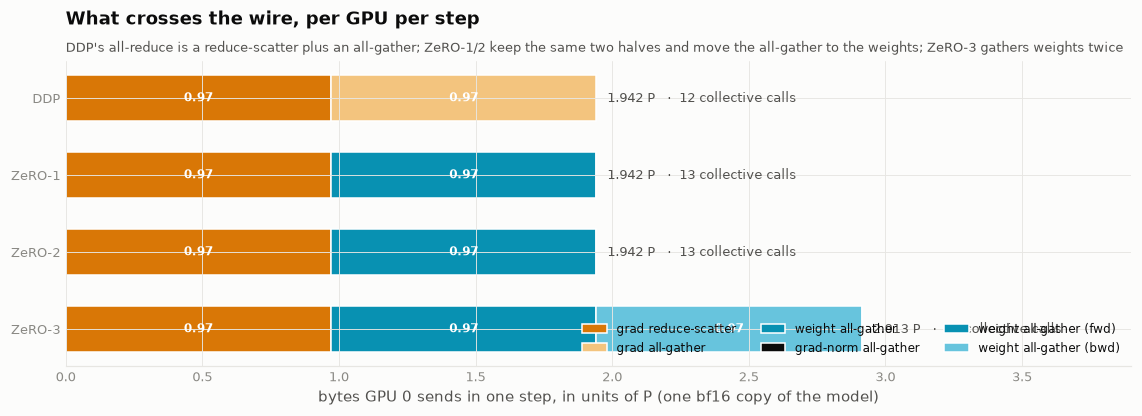

ring hops: GPU 0 → 1 over nvlink · GPU 7 → 8 over ib · GPU 8 → 9 over nvlink · GPU 31 → 0 over ib
GPU 7's bytes went over: ['ib']


In [13]:
rows = []
for st in range(4):
    r = R[st]
    per = {}
    for k, v in r.sent(0).items():
        lab, link = k.split('|')
        per[lab] = per.get(lab, 0) + v
    row = {'arrangement': NAMES[st]}
    row.update({k: v / r.P() for k, v in per.items()})
    row['total / P'] = r.sent_total() / r.P()
    row['excl. grad-norm, / P (padded)'] = sum(v for k, v in per.items() if k != 'grad-norm all-gather') / r.P(padded=True)
    row['lesson'] = f'{T.comm_P(st)}P ≈ {T.comm_P(st, WORLD):.4f}'
    row['collective calls'] = sum(r.ranks[0]['calls'].values())
    rows.append(row)
comm = pd.DataFrame(rows).set_index('arrangement').fillna(0)
display(comm.style.format(precision=4))
SUMMARY['comm'] = comm.reset_index().to_dict('records')
PL.comm_breakdown(R)
hw0 = R[0].hw
print('ring hops: ' + ' · '.join(f'GPU {r} → {(r + 1) % WORLD} over {hw0.link_kind(r, (r + 1) % WORLD)}' for r in (0, 7, 8, WORLD - 1)))
print(f"GPU 7's bytes went over: {sorted({k.split('|')[1] for k in R[0].sent(7)})}")

The grad-norm all-gather is the price of clipping when no GPU holds the whole gradient: 32 floats, 124 bytes. It is the only traffic that is not in the lesson's 2P/3P, and it is 10⁻⁴ of P.

<a id="6"></a>
## 6 · Computation and time

### The work each GPU does

In [14]:
rows = []
for st in range(4):
    r, w = R[st], R[st].ranks[0]['wall']
    rows.append({'arrangement': NAMES[st], 'fwd+bwd GFLOP / GPU / step': sum(f['fwd'] + f['bwd'] for f in r.flops) / 1e9,
                 'parameters updated by GPU 0': r.ranks[0]['opt_elems'],
                 'fraction of model': r.ranks[0]['opt_elems'] / r.psi_padded,
                 'CPU ms in forward / step': 1e3 * w['fwd'] / STEPS, 'CPU ms in backward / step': 1e3 * w['bwd'] / STEPS,
                 'CPU ms in optimizer / step': 1e3 * w['opt'] / STEPS})
work = pd.DataFrame(rows).set_index('arrangement')
display(work)
SUMMARY['work'] = work.reset_index().to_dict('records')

,fwd+bwd GFLOP / GPU / step,parameters updated by GPU 0,fraction of model,CPU ms in forward / step,CPU ms in backward / step,CPU ms in optimizer / step
arrangement,,,,,,
DDP,1.3382,820224,1.0000,472.4100,263.2393,113.6623
ZeRO-1,1.3382,25632,0.0312,506.6250,268.8431,88.3431
ZeRO-2,1.3382,25632,0.0312,500.8547,265.3902,81.1535
ZeRO-3,1.3382,25632,0.0312,511.5755,276.3567,92.6601


The forward and backward FLOPs are identical in all four. ZeRO never divides the model's *arithmetic*, only its *storage*. What it does divide is the optimizer: under ZeRO-1/2/3 each GPU updates 1/32 of the parameters, and the CPU time of the update falls with it (measured, on this laptop). In DDP, 31 of every 32 Adam updates are a GPU redoing what its neighbours are also doing; that redundant work is the "R" ZeRO removes.

### A step on the clock: does the network hide behind the compute?

My virtual card's speed is calibrated so that one toy step has the same compute-to-communication ratio as the lesson's step (1M tokens on 64 cards, Section 5). That ratio does not depend on model size, only on tokens per GPU and FLOP/s per byte/s. So, with nothing overlapped, DDP should spend **34%** (H100) and **77%** (B200) of its compute time again on the network, times (N−1)/N for the ring.

,card,arrangement,overlap,compute µs,optimizer µs,network adds µs,step µs,network / compute
0,H100,DDP,False,193.712,6.856,63.567,264.135,0.328
1,H100,DDP,True,193.712,6.856,16.705,217.273,0.086
2,H100,ZeRO-1,False,193.712,0.214,63.570,257.496,0.328
3,H100,ZeRO-1,True,193.712,0.214,16.708,210.634,0.086
4,H100,ZeRO-2,False,193.712,0.214,63.570,257.496,0.328
5,H100,ZeRO-2,True,193.712,0.214,16.708,210.634,0.086
6,H100,ZeRO-3,False,193.712,0.214,95.354,289.280,0.492
7,H100,ZeRO-3,True,193.712,0.214,23.510,217.436,0.121
8,B200,DDP,False,84.962,2.871,63.567,151.400,0.748
9,B200,DDP,True,84.962,2.871,20.551,108.384,0.242


H100: DDP, no overlap, network/compute = 32.8%   lesson 33.8% × (N−1)/N = 32.7%
B200: DDP, no overlap, network/compute = 74.8%   lesson 76.9% × (N−1)/N = 74.5%


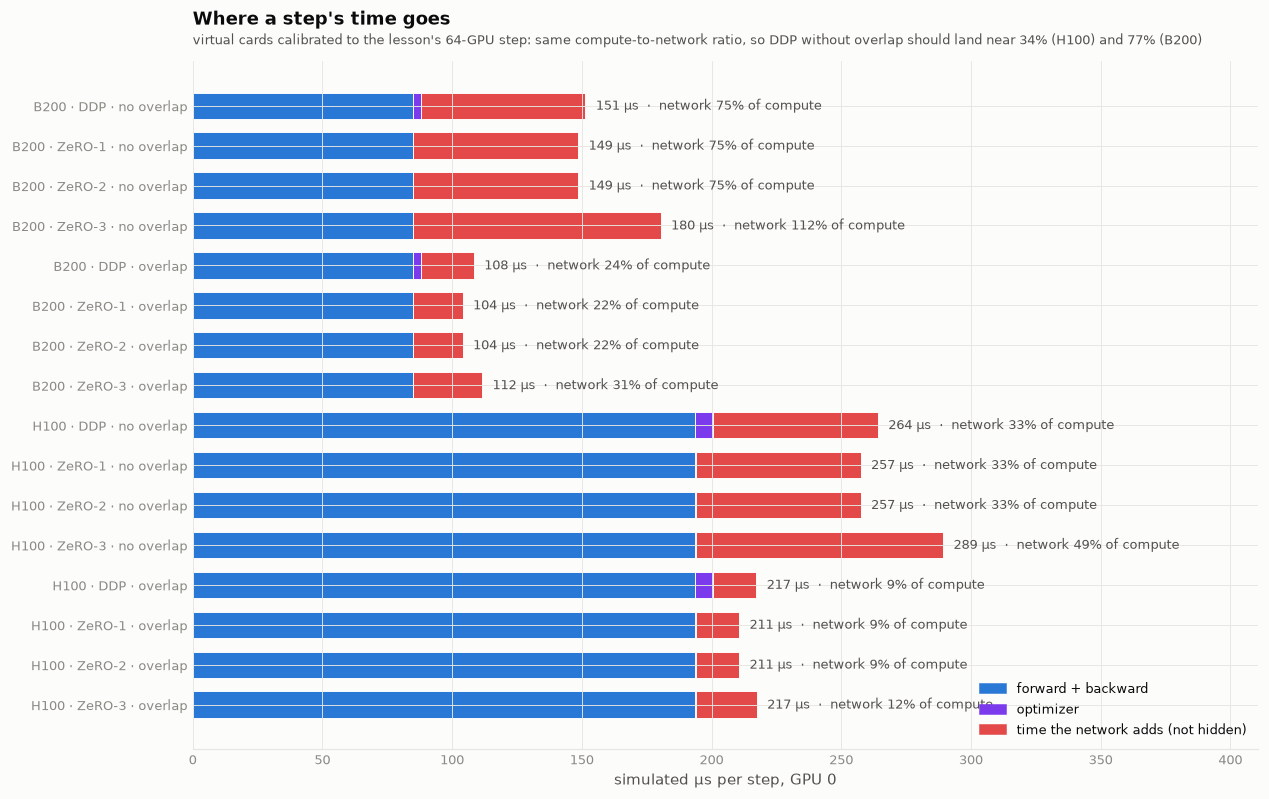

In [15]:
TM = {(card, st, ov): run(RunCfg(stage=st, world=WORLD, steps=3, card=card, overlap=ov, prefetch=ov), data, quiet=True, keep_weights=False)
      for card in ('H100', 'B200') for st in range(4) for ov in (False, True)}
rows, bars = [], []
for (card, st, ov), r in TM.items():
    comp = r.compute_time()
    opt = r.ranks[0]['opt_elems'] * ADAM_BYTES / r.hw.hbm
    exposed = r.step_time() - comp - opt
    rows.append({'card': card, 'arrangement': NAMES[st], 'overlap': ov, 'compute µs': comp * 1e6, 'optimizer µs': opt * 1e6,
                 'network adds µs': exposed * 1e6, 'step µs': r.step_time() * 1e6, 'network / compute': exposed / comp})
    bars.append({'label': f'{card} · {NAMES[st]} · {"overlap" if ov else "no overlap"}', 'compute': comp * 1e6,
                 'optimizer': opt * 1e6, 'exposed': max(exposed, 0) * 1e6, 'total': r.step_time() * 1e6})
timing = pd.DataFrame(rows)
display(timing.style.format(precision=3))
for card, lesson in (('H100', 2.40 / 7.10), ('B200', 2.40 / 3.12)):
    got = timing.query('card == @card and arrangement == "DDP" and overlap == False')['network / compute'].item()
    print(f'{card}: DDP, no overlap, network/compute = {got:.1%}   lesson {lesson:.1%} × (N−1)/N = {lesson * (WORLD - 1) / WORLD:.1%}')
SUMMARY['timing'] = rows
SITE['timing'] = rows
def tl_json(r, rank=0):
    t0 = r.ranks[rank]['step_start'][r.cfg.record_step]
    return {'events': [[e[0], e[1], round((e[2] - t0) * 1e6, 4), round((e[3] - t0) * 1e6, 4)] for e in r.ranks[rank]['events']],
            'step': r.step_time() * 1e6, 'compute': r.compute_time() * 1e6}
SITE['tl'] = {f'{card}|{st}|{int(ov)}': tl_json(r) for (card, st, ov), r in TM.items()}
PL.step_time_bars(sorted(bars, key=lambda b: (b['label'].split(' · ')[0], b['label'].split(' · ')[2] == 'overlap')))

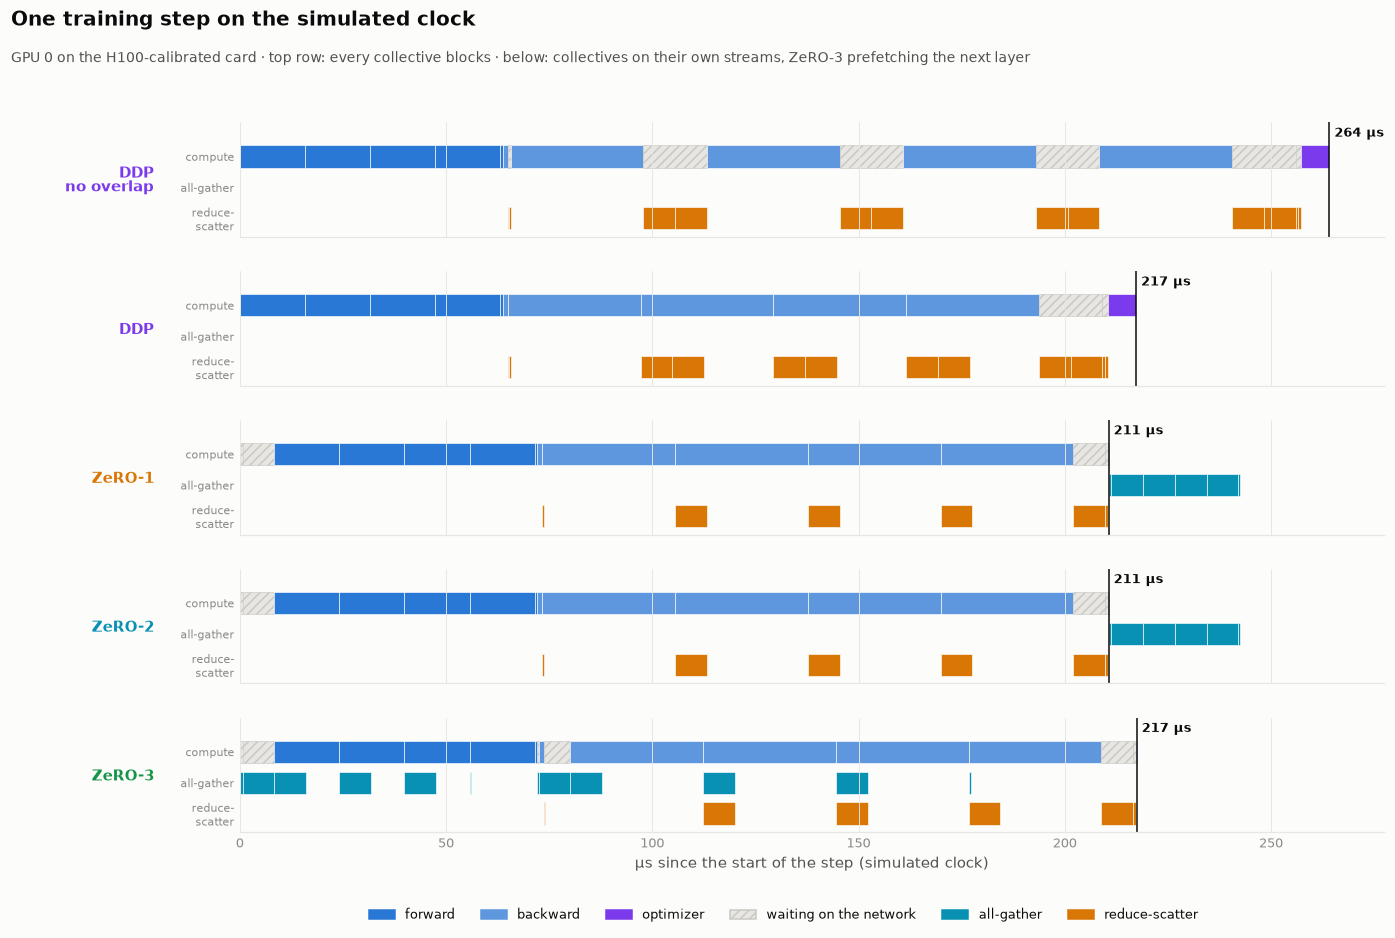

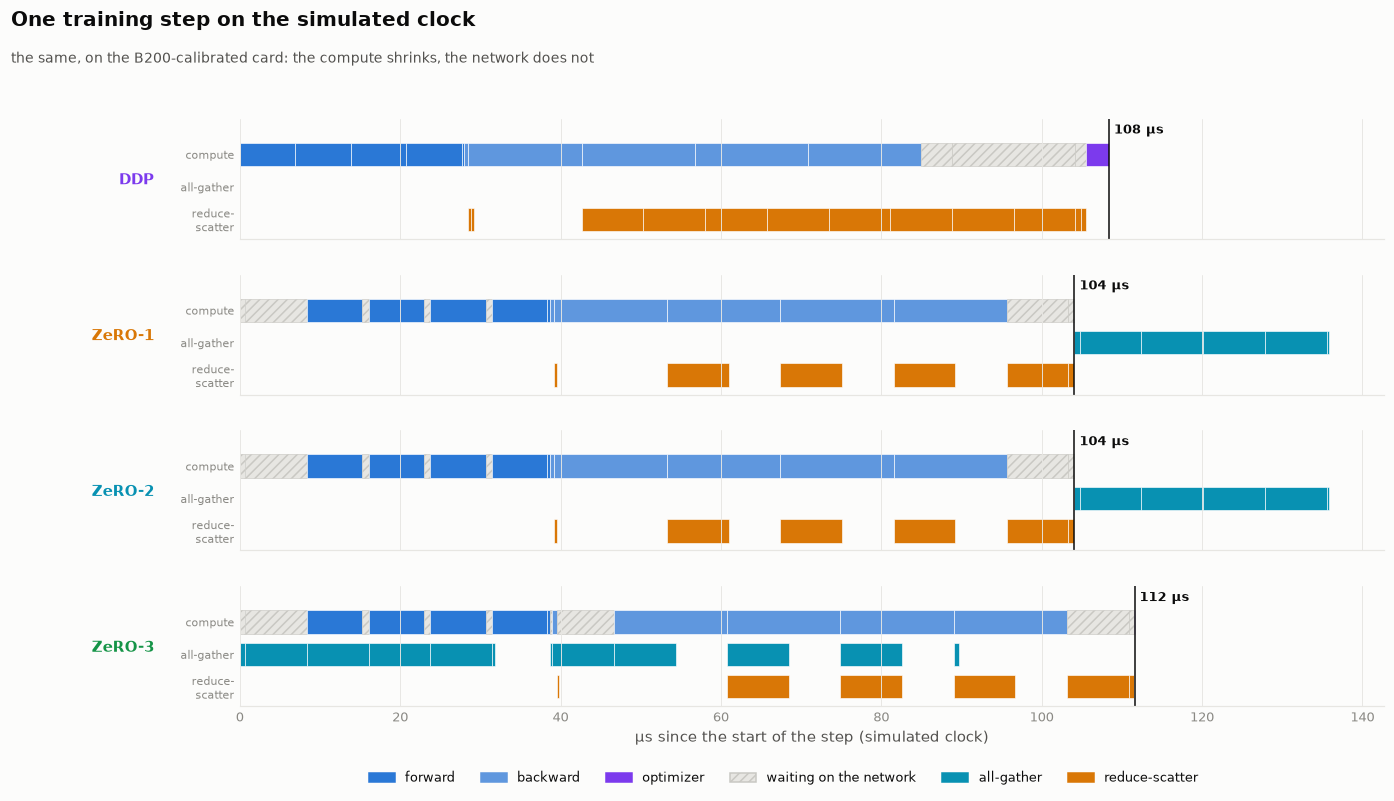

In [16]:
PL.timelines([(f'DDP\nno overlap', TM[('H100', 0, False)], 0)] + [(NAMES[st], TM[('H100', st, True)], 0) for st in range(4)],
             sub='GPU 0 on the H100-calibrated card · top row: every collective blocks · below: collectives on their own streams, '
                 'ZeRO-3 prefetching the next layer')
PL.timelines([(NAMES[st], TM[('B200', st, True)], 0) for st in range(4)], name='08b_timeline_B200',
             sub='the same, on the B200-calibrated card: the compute shrinks, the network does not')

### How many GPUs per node?

The same 32 GPUs wired three ways: one 32-GPU NVLink domain (the NVL72 idea), 4 nodes of 8, and 32 single-GPU machines. Collectives block (no overlap, no prefetch) so the table shows the raw network cost.

In [17]:
GPNS = [WORLD, 8, 1] if not QUICK else [WORLD, 4, 1]
TOPO = {(g, st): run(RunCfg(stage=st, world=WORLD, gpus_per_node=g, steps=3, overlap=False, prefetch=False), data, quiet=True, keep_weights=False)
        for g in GPNS for st in range(4)}
rows = []
for (g, st), r in TOPO.items():
    comp = r.compute_time()
    opt = r.ranks[0]['opt_elems'] * ADAM_BYTES / r.hw.hbm
    rows.append({'layout': f'{WORLD // g} node(s) × {g}', 'arrangement': NAMES[st],
                 'network µs': (r.step_time() - comp - opt) * 1e6, 'network / compute': (r.step_time() - comp - opt) / comp})
topo = pd.DataFrame(rows).pivot(index='arrangement', columns='layout', values='network / compute')
display(topo.style.format('{:.1%}'))
SUMMARY['topology'] = rows
SITE['topology'] = rows

layout,1 node(s) × 32,32 node(s) × 1,4 node(s) × 8
arrangement,,,
DDP,3.6%,32.8%,32.8%
ZeRO-1,3.6%,32.8%,32.8%
ZeRO-2,3.6%,32.8%,32.8%
ZeRO-3,5.5%,49.2%,49.2%


A flat ring runs at the speed of its slowest hop. With 4 nodes only 4 of the 32 hops cross InfiniBand, yet those 4 set the pace: **4 × 8 costs exactly as much as 32 × 1**. Putting more GPUs in a node does not help a flat ring until *every* hop is NVLink. That is why real libraries use hierarchical collectives (reduce inside the node first, so only 1/8 of the data crosses the slow link), and it is the real content of the lesson's open question "how many GPUs per node".

<a id="7"></a>
## 7 · Offload to the CPU

ZeRO-Offload keeps the fp32 master copy and Adam's m and v in the node's system memory and runs the update on the CPU. Each step the GPU sends its gradient slice down PCIe and gets its updated bf16 weight slice back.

In [18]:
rows = []
for r in [R[1], OFF[1], R[2], OFF[2], R[3], OFF[3]]:
    pc = sum(v for k, v in r.sent(0).items() if k.endswith('|pcie'))
    rows.append({'arrangement': r.cfg.name, 'GPU MiB': r.gpu_bytes() / 2**20,
                 'CPU MiB (per GPU)': sum(r.ranks[0]['host_steady'].values()) / 2**20,
                 'GPU B/param': r.bytes_per_param(), 'PCIe KiB / step': pc / 1024,
                 'step µs (H100, overlap)': r.step_time() * 1e6})
off = pd.DataFrame(rows).set_index('arrangement')
display(off.style.format(precision=3))
SUMMARY['offload'] = off.reset_index().to_dict('records')

,GPU MiB,CPU MiB (per GPU),GPU B/param,PCIe KiB / step,"step µs (H100, overlap)"
arrangement,,,,,
ZeRO-1,3.422,0.000,4.386,0.000,210.634
ZeRO-1 + offload,3.129,0.293,4.010,100.125,218.469
ZeRO-2,1.907,0.000,2.443,0.000,210.634
ZeRO-2 + offload,1.613,0.293,2.067,100.125,218.469
ZeRO-3,0.391,0.000,0.501,0.000,217.436
ZeRO-3 + offload,0.098,0.293,0.125,100.125,226.108


<a id="8"></a>
## 8 · Scaling to V5: 30 billion parameters

Nothing in a bytes-per-parameter figure depends on the model size, so the per-GPU memory of a 30B model under each arrangement is my measured bytes/param × 30 × 10⁹. The table puts that next to the lesson's Section 7 table.

,8 GPUs,16 GPUs,32 GPUs,64 GPUs,first fits on 74.5 GiB
arrangement,,,,,
DDP,447.0 ✓,447.0 ✓,447.0 ✓,447.0* ✓,never
ZeRO-1,153.7 ✓,132.7 ✓,122.2 ✓,117.0* ✓,never
ZeRO-2,104.8 ✓,80.3 ✓,68.1 ✓,62.0* ✓,32 GPUs
ZeRO-3,55.9 ✓,27.9 ✓,14.0 ✓,7.0* ✓,8 GPUs


* = formula only (my sweep stops at N = 32 )   ✓ = matches the lesson to 0.1 GiB
ZeRO-1 floor: bf16 weights + gradients = 4 B/param = 111.8 GiB at any N; that alone fills a card at 20.0B parameters


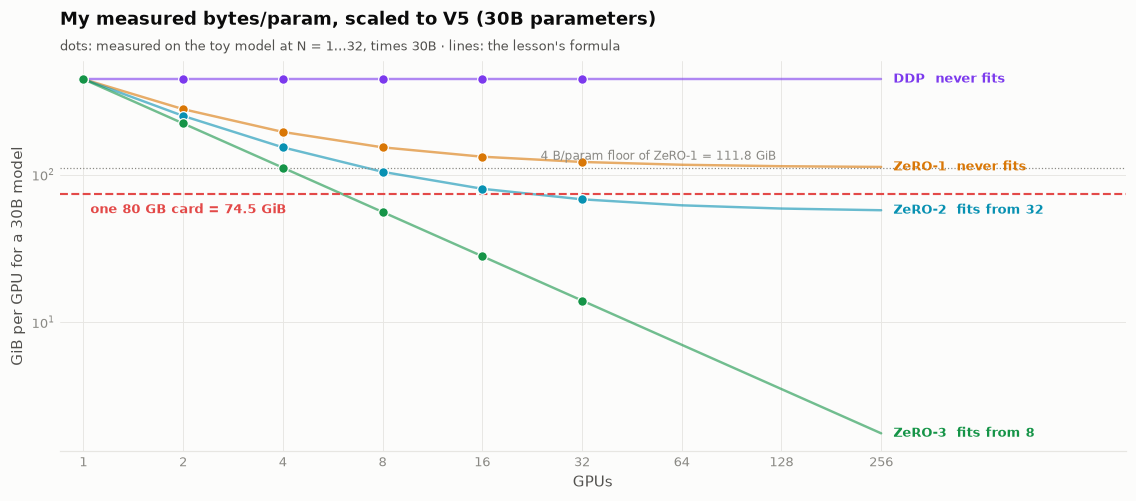

In [19]:
lesson7 = {0: {8: 447.0, 16: 447.0, 32: 447.0, 64: 447.0}, 1: {8: 153.7, 16: 132.7, 32: 122.2, 64: 117.0},
           2: {8: 104.8, 16: 80.3, 32: 68.1, 64: 62.0}, 3: {8: 55.9, 16: 27.9, 32: 14.0, 64: 7.0}}
measured = {st: {n: SW[(st, n)].bytes_per_param(padded=True) for n in NS} for st in range(4)}
rows = []
for st in range(4):
    row = {'arrangement': NAMES[st]}
    for n in (8, 16, 32, 64):
        mine = measured[st][n] * 30e9 / GIB if n in measured[st] else T.gib_per_gpu(st, n)
        row[f'{n} GPUs'] = f'{mine:.1f}' + ('' if n in measured[st] else '*') + (' ✓' if abs(mine - lesson7[st][n]) < 0.05 else f' (lesson {lesson7[st][n]})')
    ff = T.first_fit(st)
    row['first fits on 74.5 GiB'] = f'{ff} GPUs' if ff else 'never'
    rows.append(row)
display(pd.DataFrame(rows).set_index('arrangement'))
print('* = formula only (my sweep stops at N =', max(NS), ')   ✓ = matches the lesson to 0.1 GiB')
print(f'ZeRO-1 floor: bf16 weights + gradients = 4 B/param = {30e9 * 4 / GIB:.1f} GiB at any N; '
      f'that alone fills a card at {T.replicated_floor_params() / 1e9:.1f}B parameters')
SITE['ladder'] = {str(st): measured[st] for st in range(4)}
PL.ladder(measured)

<a id="9"></a>
## 9 · Reality check: PyTorch's own ZeRO on 32 real processes

My simulator could be consistently wrong. So the same model, data, init and AdamW ran on **32 real processes** with `torch.distributed` (gloo, CPU) on Modal (`modal run tools/modal_app.py::main`), using PyTorch's implementations instead of mine:

* **DDP:** `DistributedDataParallel`
* **ZeRO-1:** `torch.distributed.optim.ZeroRedundancyOptimizer`
* **ZeRO-2 analogue:** FSDP2 `fully_shard(reshard_after_forward=False)`, which gathers the weights once and keeps them through backward
* **ZeRO-3:** FSDP2 `fully_shard()`, the lesson's recommended path

Everything is fp32 there (gloo on CPU), so the state is 4 + 4 + 8 = 16 B/param and P = 4Ψ. Each rank measured the bytes of the tensors it holds and the payload of every collective it called.

DDP [fp32]             N=32  20.048 B/param  sent 1.942 P  loss 2.5871  (115s)


,torch,params B/p,grads B/p,AdamW B/p,total B/p (rank 0),AdamW state: max/min over ranks,collectives,ring bytes / rank / P,final loss,max |loss − my sim|
strategy,,,,,,,,,,
ddp,2.15.0+cpu,4.0000,4.0000,8.0000,16.0000,1.0000,all_reduce 1.00P,1.9375,2.5871,7.1526e-07
zero1,2.15.0+cpu,4.0000,4.0000,0.6408,8.6408,128.0000,"all_reduce 1.00P, broadcast 1.00P",2.9062,2.5871,7.1526e-07
fsdp2_zero2,2.15.0+cpu,0.1262,0.1262,0.2524,0.5049,1.0308,"all_gather_single 1.01P, reduce_scatter_single...",1.9564,2.5871,7.1526e-07
fsdp2_zero3,2.15.0+cpu,0.1262,0.1262,0.2524,0.5049,1.0308,"all_gather_single 2.02P, reduce_scatter_single...",2.9345,2.5871,7.1526e-07


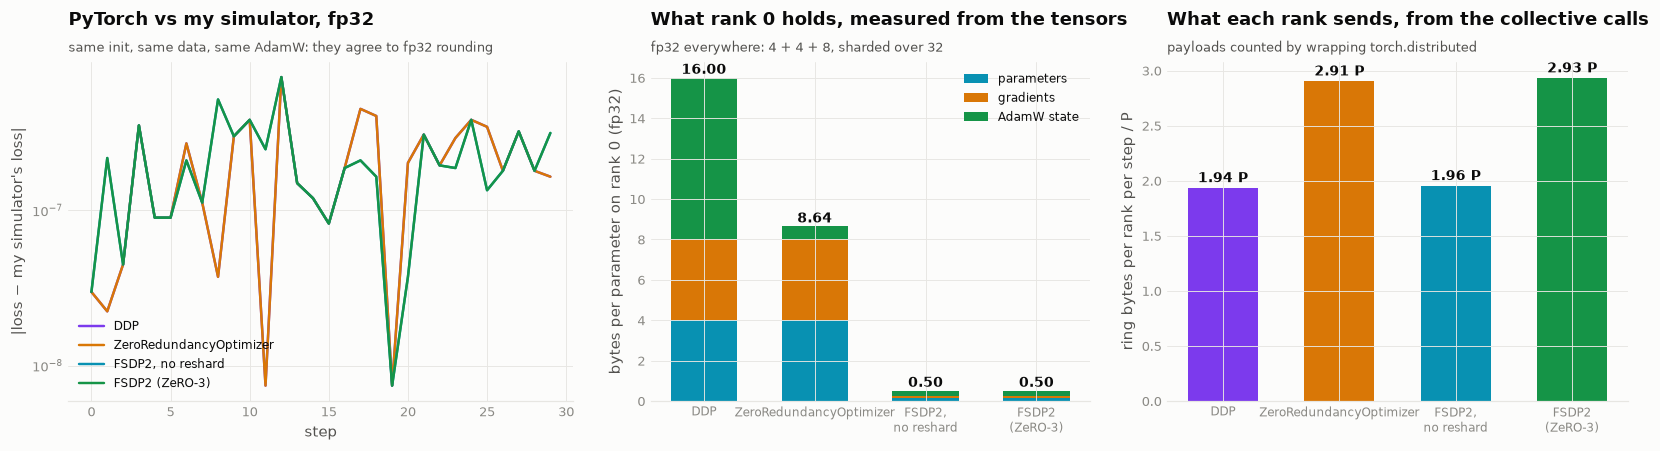

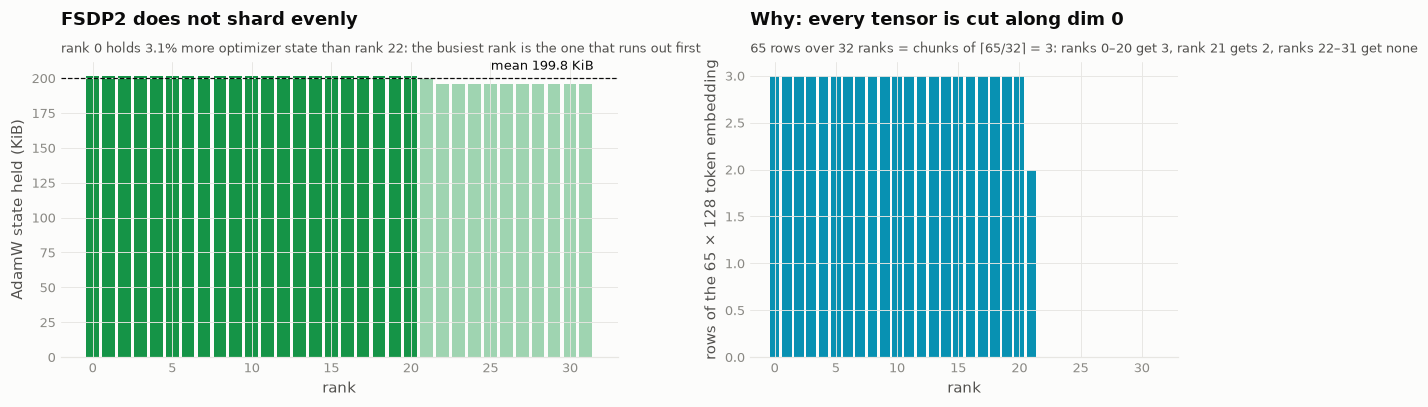

In [20]:
REAL_PATH = Path('results/real_dist.json')
REAL = json.loads(REAL_PATH.read_text()) if REAL_PATH.exists() else None
if REAL:
    RW, RS = REAL['ddp']['world'], REAL['ddp']['steps']
    SIM32 = run(RunCfg(stage=0, world=RW, steps=RS, dtype='fp32'), data, keep_weights=False)
    rows = []
    for k, r in REAL.items():
        psi, W = r['psi'], r['world']
        per = r['ranks'][0]
        opt = [x['opt'] for x in r['ranks']]
        ring = sum(v * (2 if op == 'all_reduce' else 1) * (W - 1) / W for op, v in per['comm_bytes'].items())
        rows.append({'strategy': k, 'torch': r['torch'], 'params B/p': per['params'] / psi, 'grads B/p': per['grads'] / psi,
                     'AdamW B/p': per['opt'] / psi, 'total B/p (rank 0)': (per['params'] + per['grads'] + per['opt']) / psi,
                     'AdamW state: max/min over ranks': max(opt) / min(opt),
                     'collectives': ', '.join(f'{op} {v / (4 * psi):.2f}P' for op, v in per['comm_bytes'].items()),
                     'ring bytes / rank / P': ring / (4 * psi), 'final loss': r['losses'][-1],
                     'max |loss − my sim|': float(np.max(np.abs(np.array(r['losses']) - np.array(SIM32.losses))))})
    realtab = pd.DataFrame(rows).set_index('strategy')
    display(realtab)
    SUMMARY['real'] = realtab.reset_index().to_dict('records')
    SITE['real'] = SUMMARY['real']
    SITE['real_detail'] = {k: {'losses': r['losses'], 'opt': [x['opt'] for x in r['ranks']],
                               'params': [x['params'] for x in r['ranks']],
                               'tok_rows': [PL.tok_rows(x['local_numel']) for x in r['ranks']]}
                           for k, r in REAL.items()}
    SITE['sim32_losses'] = SIM32.losses
    PL.real_vs_sim(REAL, SIM32)
    PL.fsdp_imbalance(REAL)
else:
    print('results/real_dist.json not found: run `modal run tools/modal_app.py::main` first')

<a id="10"></a>
## 10 · What I would pick, and why

In [21]:
z = {st: R[st] for st in range(4)}
md(f'''
| | memory / GPU (here, N={WORLD}) | sent / GPU / step | what it costs | when I would use it |
|---|---|---|---|---|
| **DDP** | {z[0].bytes_per_param():.2f} B/param | {z[0].sent_total() / z[0].P():.2f} P | 15/16 of every card is a copy of another card | the model *and* Adam fit on one card; simplest, fastest |
| **ZeRO-1** | {z[1].bytes_per_param():.2f} B/param | {z[1].sent_total() / z[1].P():.2f} P | nothing extra on the wire; still 4 B/param of weights + gradients on every card | almost always better than DDP: free memory |
| **ZeRO-2** | {z[2].bytes_per_param():.2f} B/param | {z[2].sent_total() / z[2].P():.2f} P | bucketed reduce-scatter in backward; bf16 weights still replicated (2 B/param floor) | the default when weights fit but Adam does not; V4 ran this |
| **ZeRO-3** | {z[3].bytes_per_param():.2f} B/param | {z[3].sent_total() / z[3].P():.2f} P | +50% traffic, a gather before every layer twice a step; needs prefetch to hide it | the model itself does not fit; V5 at 30B on fewer than 32 cards |
''')


| | memory / GPU (here, N=32) | sent / GPU / step | what it costs | when I would use it |
|---|---|---|---|---|
| **DDP** | 16.04 B/param | 1.94 P | 15/16 of every card is a copy of another card | the model *and* Adam fit on one card; simplest, fastest |
| **ZeRO-1** | 4.39 B/param | 1.94 P | nothing extra on the wire; still 4 B/param of weights + gradients on every card | almost always better than DDP: free memory |
| **ZeRO-2** | 2.44 B/param | 1.94 P | bucketed reduce-scatter in backward; bf16 weights still replicated (2 B/param floor) | the default when weights fit but Adam does not; V4 ran this |
| **ZeRO-3** | 0.50 B/param | 2.91 P | +50% traffic, a gather before every layer twice a step; needs prefetch to hide it | the model itself does not fit; V5 at 30B on fewer than 32 cards |


In [22]:
def jsonable(o):
    if isinstance(o, dict): return {str(k): jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [jsonable(v) for v in o]
    if isinstance(o, (np.floating, np.integer)): return o.item()
    if isinstance(o, float) and not math.isfinite(o): return None
    return o

SITE['stages'] = {}
for key, r in [(str(st), R[st]) for st in range(4)] + [(f'off{st}', OFF[st]) for st in (2, 3)]:
    tm = TM[('H100', r.cfg.stage, True)] if not r.cfg.offload else r
    SITE['stages'][key] = {
        'name': r.cfg.name, 'stage': r.cfg.stage, 'offload': r.cfg.offload, 'bpp': r.bytes_per_param(padded=True),
        'formula': T.bytes_per_param(r.cfg.stage, WORLD, offload=r.cfg.offload), 'psi': r.psi, 'P': r.P(),
        'steady': [x['steady'] for x in r.ranks], 'host': r.ranks[0]['host_steady'], 'peak': r.ranks[0]['peak'],
        'peak_phase': r.ranks[0]['peak_phase'], 'trace': r.ranks[0]['trace'], 'sent': r.sent(0), 'calls': r.ranks[0]['calls'],
        'events': [list(e) for e in tm.ranks[0]['events']], 'step_start': tm.ranks[0]['step_start'][tm.cfg.record_step],
        'step_time': tm.step_time(), 'compute_time': tm.compute_time()}
Path('results').mkdir(exist_ok=True)
Path(f'results/summary.{PROFILE}.json').write_text(json.dumps(jsonable(SUMMARY), indent=1))
Path(f'results/site.{PROFILE}.json').write_text(json.dumps(jsonable(SITE)))
print('wrote results/summary.%s.json and results/site.%s.json' % (PROFILE, PROFILE))

wrote results/summary.full.json and results/site.full.json
